In [72]:
# importing the functions
import pandas as pd
import numpy as np
import time as tm
from scipy.stats import chi2_contingency
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

# to display plots in Jupyter notebook
%matplotlib inline
plt.rcParams['font.size'] = '12'

In [73]:
from google.colab import files
uploaded = files.upload()

Saving model_dataset 1.xlsx to model_dataset 1 (3).xlsx


In [74]:
df = pd.read_excel('model_dataset 1.xlsx', sheet_name=1)
df.dtypes

,0
site_id,object
survey_batch_id,int64
source_location_id,object
location_id,object
road_no,object
slk_km,float64
road_name,object
survey_location_name,object
latitude,float64
longitude,float64


In [75]:
cat_cols = [
    'abs_mb_category_2021',
    'pta_nearest_active_stop_type',
    'health_nearest_establishment_category',
    'health_nearest_establishment_type',
    'education_nearest_school_sector',
    'education_nearest_school_low_year',
    'education_nearest_school_high_year',
]

num_cols = [
    'abs_mb_area_sqkm_2021',
    'abs_mb_dwellings_2021',
    'abs_mb_persons_usual_resident_2021',
    'abs_mb_dwellings_per_sqkm_2021',
    'abs_mb_persons_per_sqkm_2021',
    'pta_nearest_active_stop_distance_m',
    'pta_active_stops_within_500m',
    'health_nearest_establishment_distance_m',
    'education_nearest_active_school_distance_m',
    'ms_building_count_500m',
    'ms_building_count_per_sqkm_500m',
    'ms_building_footprint_area_m2_500m',
    'ms_building_coverage_ratio_500m',
    'overture_food_drink_count_500m',
    'overture_grocery_convenience_pharmacy_count_500m',
    'overture_other_shopping_count_500m',
    'pedestrian_crossings',
    'commercial_buildings',
    'residential_buildings',
    'industrial_buildings',
    'parking_areas'

]

bool_cols = [
    'footpath_both_sides',
    'footpath_one_side',
    'fencing_barriers',
    'railway_station',
    'bus_stops',
    'overpass_bridge',
    'park_bushland_reserve',
    'shared_pedestrian_and_cycle_path'

]

cat = df[cat_cols]
num = df[num_cols]
bool_var = df[bool_cols]
y_cross = df['obs_peak_cross_ped_per_h']
y_along = df['obs_peak_along_ped_per_h']

In [76]:
cat = df[cat_cols].copy()

cat['abs_mb_category_2021'] = cat['abs_mb_category_2021'].apply(
    lambda x: x if x in ['Residential', 'Commercial'] else 'Other'
)

In [77]:
cat.head(5)

,abs_mb_category_2021,pta_nearest_active_stop_type,health_nearest_establishment_category,health_nearest_establishment_type,education_nearest_school_sector,education_nearest_school_low_year,education_nearest_school_high_year
0,Residential,Transwa,Acute Hospital,Public,NON-GOVERNMENT,KIN,Y06
1,Other,Transwa,Acute Hospital,Public,GOVERNMENT,KIN,Y06
2,Other,School,Acute Hospital,Public,GOVERNMENT,Y07,Y12
3,Commercial,School,Acute Hospital,Public,GOVERNMENT,KIN,Y06
4,Commercial,Standard,Acute Hospital,Public,NON-GOVERNMENT,PKG,Y06


In [78]:
num.head(5)

,abs_mb_area_sqkm_2021,abs_mb_dwellings_2021,abs_mb_persons_usual_resident_2021,abs_mb_dwellings_per_sqkm_2021,abs_mb_persons_per_sqkm_2021,pta_nearest_active_stop_distance_m,pta_active_stops_within_500m,health_nearest_establishment_distance_m,education_nearest_active_school_distance_m,ms_building_count_500m,...,ms_building_footprint_area_m2_500m,ms_building_coverage_ratio_500m,overture_food_drink_count_500m,overture_grocery_convenience_pharmacy_count_500m,overture_other_shopping_count_500m,pedestrian_crossings,commercial_buildings,residential_buildings,industrial_buildings,parking_areas
0,7.9418,35,74,4.407061,9.317787,9163.3,0,29476.9,20481.040474,12,...,2320.979,0.002956,0,0,0,0,0,0,0,0
1,0.3167,0,0,0.000000,0.000000,564.3,0,2886.5,1349.539551,175,...,122504.370,0.156040,3,0,19,0,0,0,3,1
2,0.1362,0,0,0.000000,0.000000,265.0,4,1237.4,318.566350,370,...,136177.905,0.173457,19,8,35,1,6,0,0,3
3,0.0568,0,0,0.000000,0.000000,93.5,11,485.9,726.232796,392,...,98962.098,0.126053,14,13,20,0,1,7,0,2
4,0.0616,0,0,0.000000,0.000000,182.2,13,1155.7,238.181316,329,...,103975.996,0.132440,20,7,19,1,8,2,0,4


In [79]:
bool_var.head(5)

,footpath_both_sides,footpath_one_side,fencing_barriers,railway_station,bus_stops,overpass_bridge,park_bushland_reserve,shared_pedestrian_and_cycle_path
0,False,False,True,False,False,False,True,False
1,True,False,True,False,False,False,True,True
2,True,True,True,True,False,False,True,True
3,False,True,True,False,False,False,False,False
4,True,True,True,False,False,False,True,False


Commercial areas show the highest pedestrian volumes, both crossing and walking along streets. Residential zones have the lowest volumes, with few outliers near busy intersections. Other land uses fall between these extremes, indicating moderate pedestrian activity. Overall, pedestrian movement intensifies in commercial zones due to business and transit accessibility.

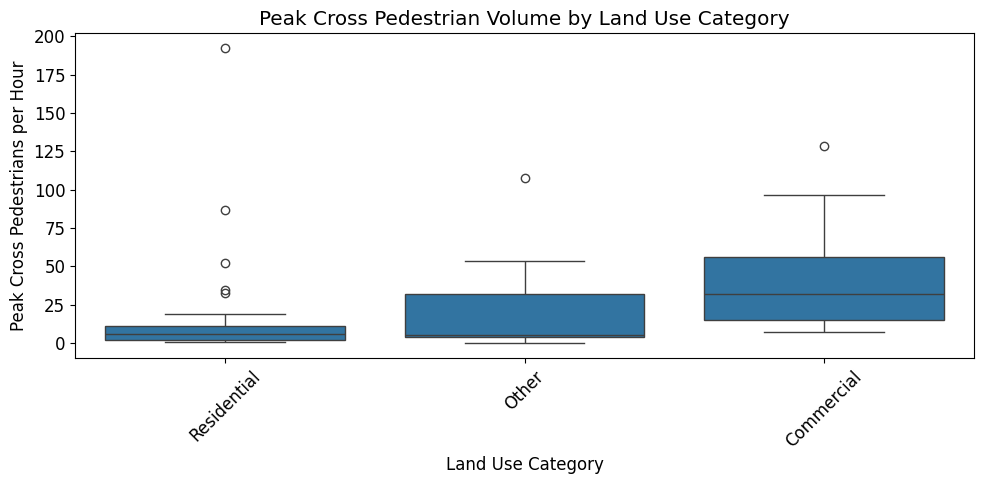

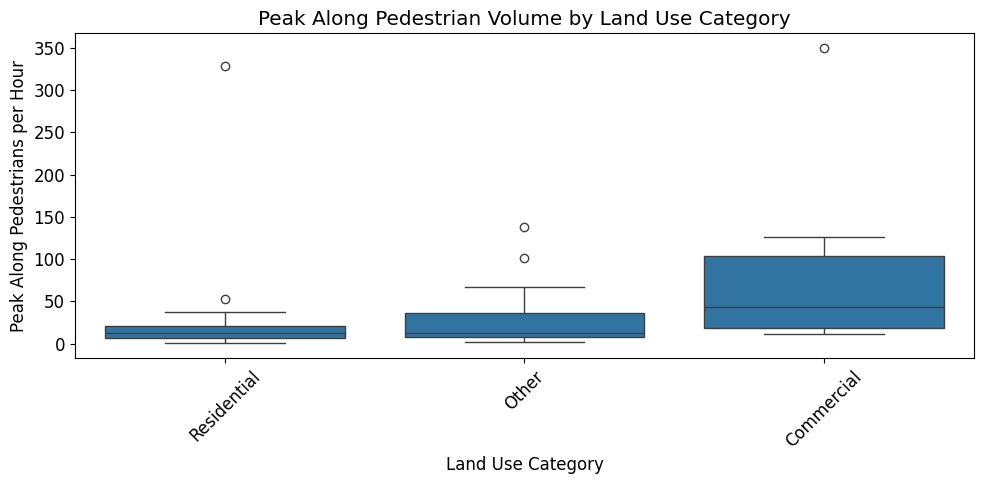

In [80]:
# Add the target variables to the categorical data
plot_df = cat.copy()
plot_df['y_cross'] = y_cross
plot_df['y_along'] = y_along

# Cross pedestrian volume by category
plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x='abs_mb_category_2021', y='y_cross')
plt.xticks(rotation=45)
plt.title('Peak Cross Pedestrian Volume by Land Use Category')
plt.xlabel('Land Use Category')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=plot_df, x='abs_mb_category_2021', y='y_along')
plt.xticks(rotation=45)
plt.title('Peak Along Pedestrian Volume by Land Use Category')
plt.xlabel('Land Use Category')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.tight_layout()
plt.show()

Pedestrian volumes appear relatively similar across Transwa, School, and Standard stop types. Most values cluster at low levels, with a few high outliers indicating occasional spikes in activity. The “along” pedestrian volumes show slightly higher variability than “cross” volumes, suggesting more movement parallel to roads near active stops. Overall, pedestrian intensity does not differ dramatically by stop type, but certain locations experience notably higher peaks.

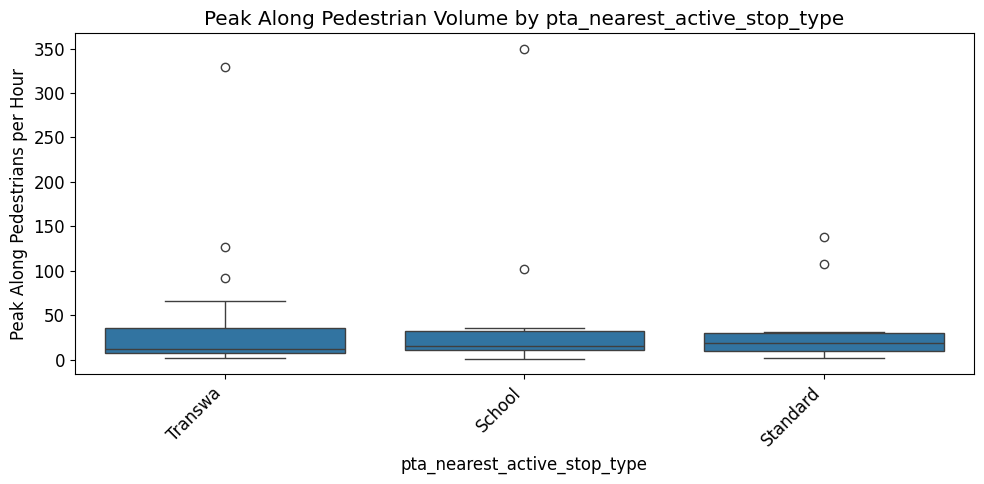

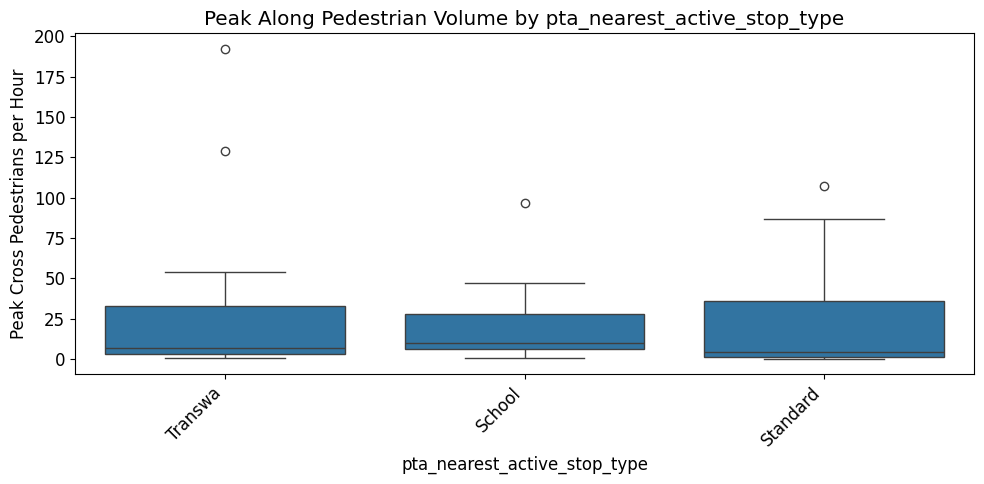

In [81]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='pta_nearest_active_stop_type',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by pta_nearest_active_stop_type')
plt.xlabel('pta_nearest_active_stop_type')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='pta_nearest_active_stop_type',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by pta_nearest_active_stop_type')
plt.xlabel('pta_nearest_active_stop_type')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Pedestrian volumes are much higher near acute hospitals than nursing posts, both for crossing and walking along streets. The distributions for hospitals show wider variability and several high outliers, indicating concentrated pedestrian activity around major health facilities. In contrast, nursing posts exhibit consistently low pedestrian volumes with minimal variation. This suggests that large hospitals attract significantly more foot traffic due to their scale and surrounding infrastructure.

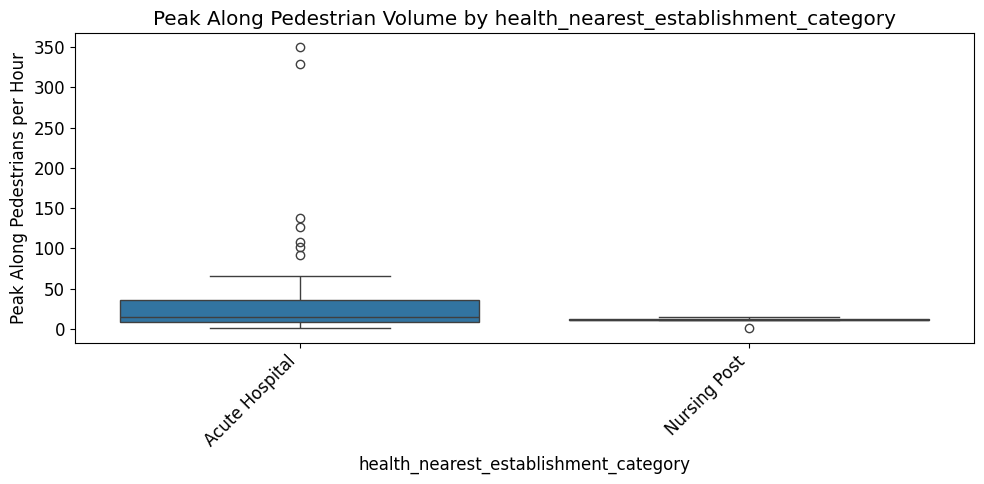

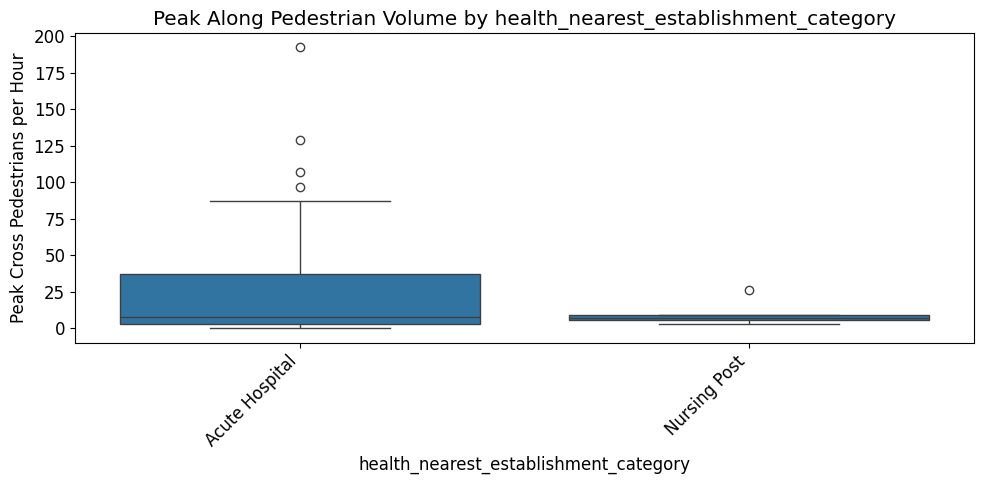

In [82]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='health_nearest_establishment_category',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by health_nearest_establishment_category')
plt.xlabel('health_nearest_establishment_category')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='health_nearest_establishment_category',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by health_nearest_establishment_category')
plt.xlabel('health_nearest_establishment_category')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Pedestrian volumes are clearly higher near public health establishments than private ones, both for crossing and walking along streets. Public facilities show a wider range and more outliers, indicating concentrated pedestrian activity and variability in foot traffic. Private establishments have lower and more consistent volumes, suggesting limited pedestrian movement around them. This pattern implies that public health centers attract more people, likely due to larger capacity and accessibility.

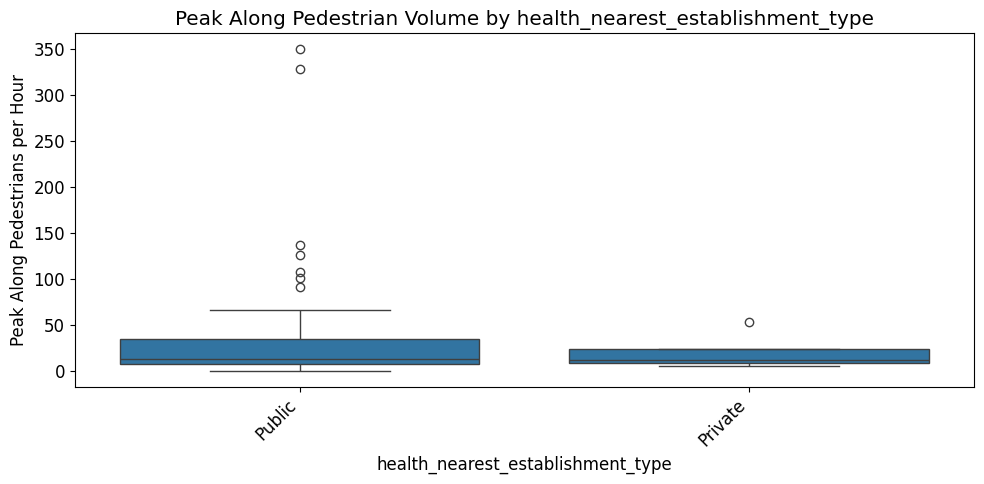

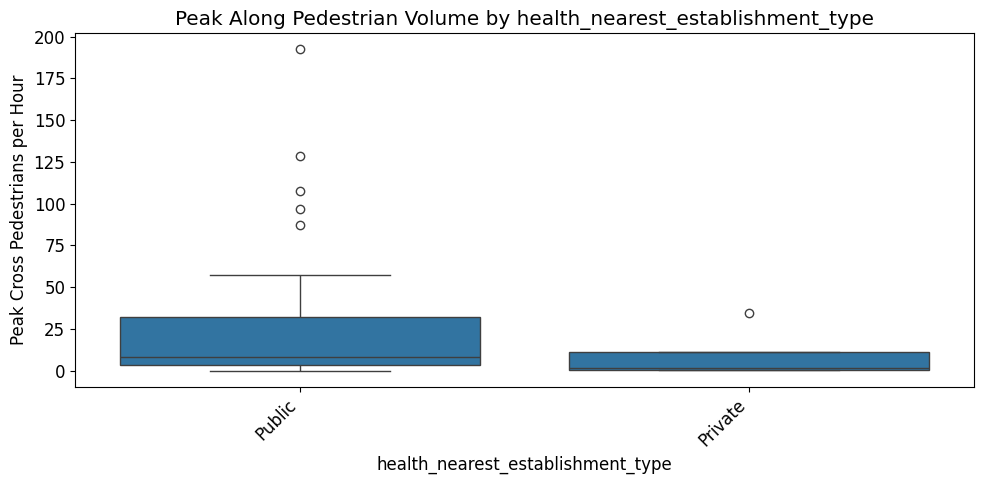

In [83]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='health_nearest_establishment_type',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by health_nearest_establishment_type')
plt.xlabel('health_nearest_establishment_type')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='health_nearest_establishment_type',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by health_nearest_establishment_type')
plt.xlabel('health_nearest_establishment_type')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

The box plots you generated show substantial overlap in pedestrian volumes across different school levels, with only very small differences in medians and ranges. This means the type of educational institution does not meaningfully shift pedestrian activity in a way that would help a regression model.

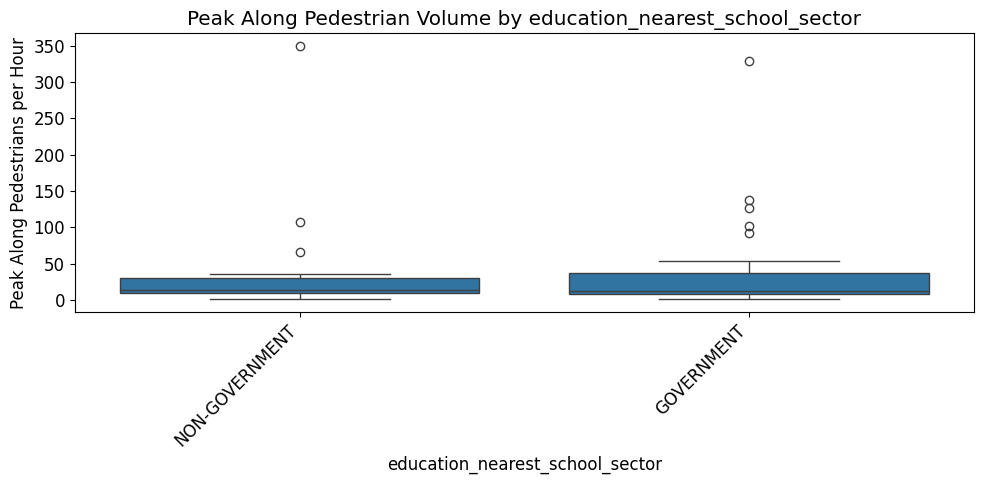

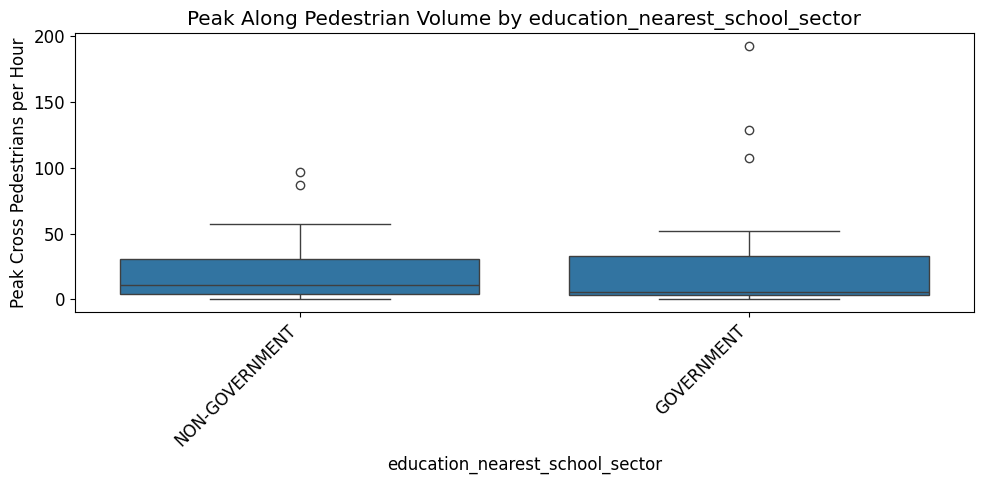

In [84]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_sector',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_sector')
plt.xlabel('education_nearest_school_sector')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_sector',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_sector')
plt.xlabel('education_nearest_school_sector')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Pedestrian volumes vary notably by school year level. For lower school years, areas near Year 7 schools show the highest pedestrian activity, both along and across streets, while kindergarten and pre‑kindergarten zones have moderate volumes and Year 10–11 zones remain minimal. For higher school years, Year 6 and Year 12 schools exhibit greater pedestrian movement, with Year 12 showing broader variability and several high outliers. Overall, pedestrian intensity tends to peak around middle‑school and senior‑school zones, reflecting larger student populations and more active surroundings.


Given the similar distributional patterns across lower‑year and higher‑year school categories, it is reasonable to consolidate them into a single categorical variable. This simplifies the model structure while still capturing overall school‑related pedestrian activity. The combined variable reduces redundancy and improves interpretability without materially affecting the underlying trends.

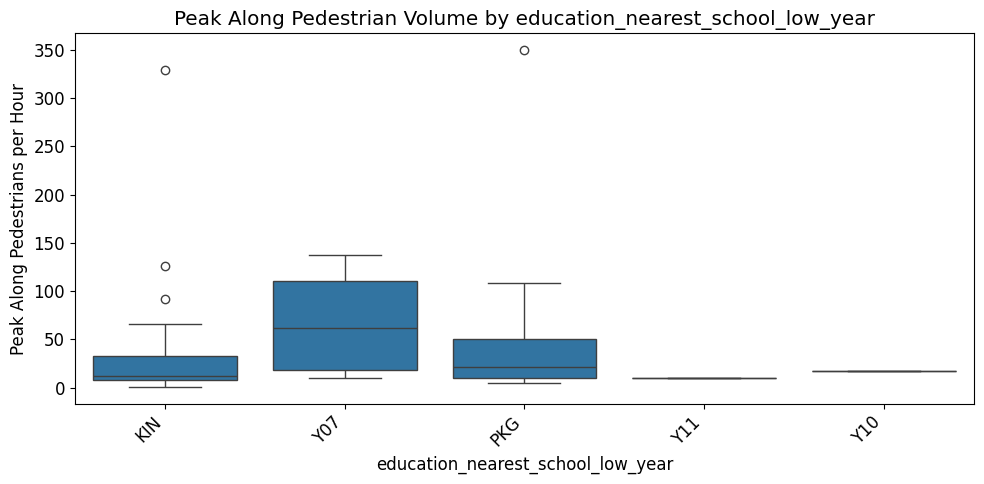

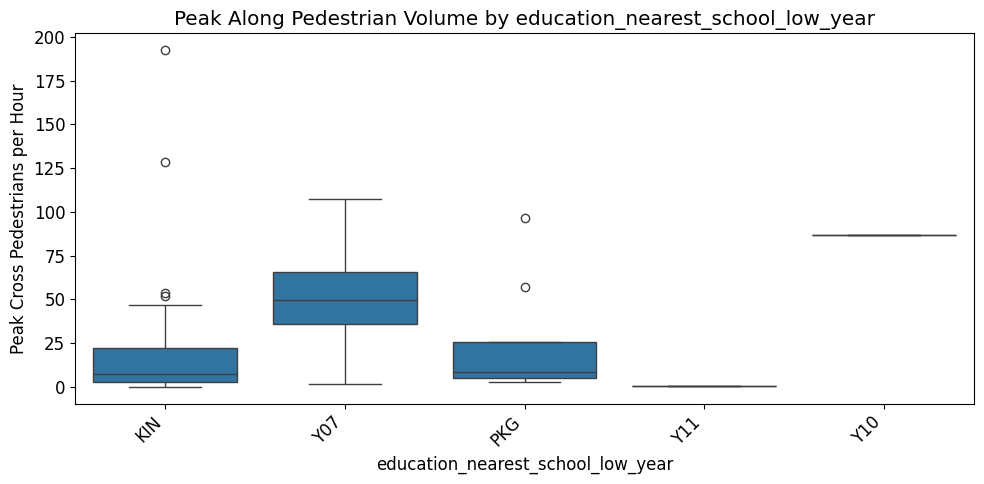

In [85]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_low_year',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_low_year')
plt.xlabel('education_nearest_school_low_year')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_low_year',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_low_year')
plt.xlabel('education_nearest_school_low_year')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

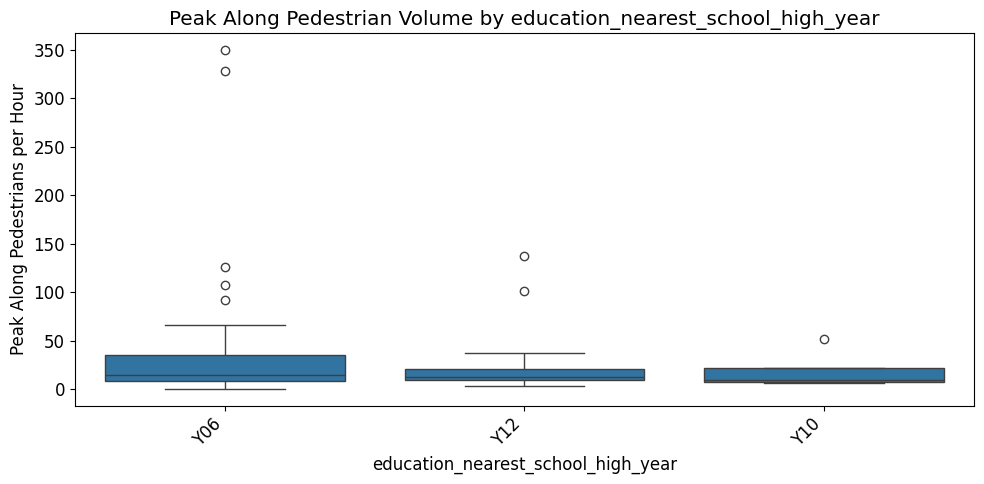

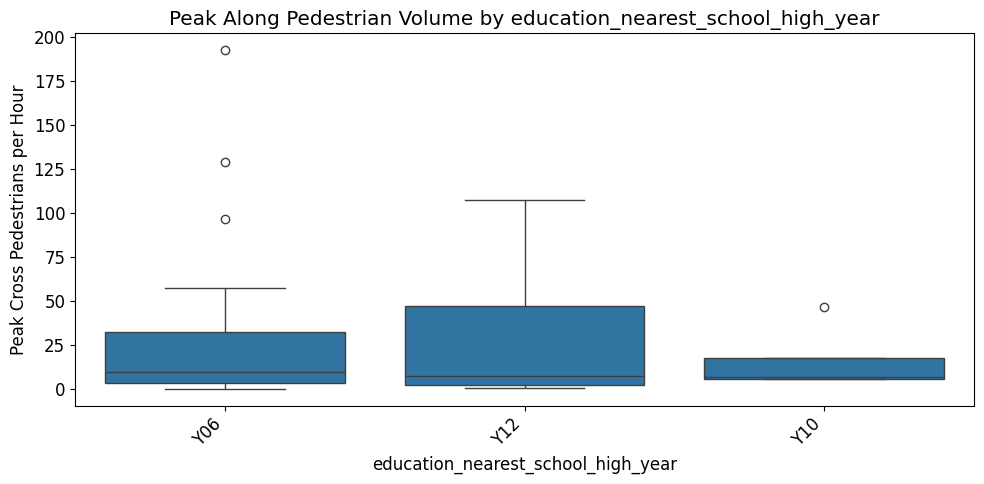

In [86]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_high_year',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_high_year')
plt.xlabel('education_nearest_school_high_year')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df,
        x='education_nearest_school_high_year',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_nearest_school_high_year')
plt.xlabel('education_nearest_school_high_year')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [87]:
df_copy = df.copy()

df_copy['education_school_level'] = (
    df_copy['education_nearest_school_low_year']
    .isin(['Y10', 'Y11', 'Y12'])
    |
    df_copy['education_nearest_school_high_year']
    .isin(['Y10', 'Y11', 'Y12'])
).map({
    True: 'High',
    False: 'Low'
})

df_copy = df_copy.drop(columns=[
    'education_nearest_school_low_year',
    'education_nearest_school_high_year'
])

The box plots show only small differences between low‑ and high‑level schools, with substantial overlap in their pedestrian‑volume distributions. High‑level schools have slightly higher medians, but the effect size is modest and unlikely to strongly influence a regression model. Low‑level schools contribute more variability and occasional spikes, yet this inconsistency does not translate into a clear predictive pattern. Overall, the relationship between school level and pedestrian volume appears weak compared with other variables in your dataset. This suggests the variable will have limited importance in regression and may be included only as a minor contextual control.

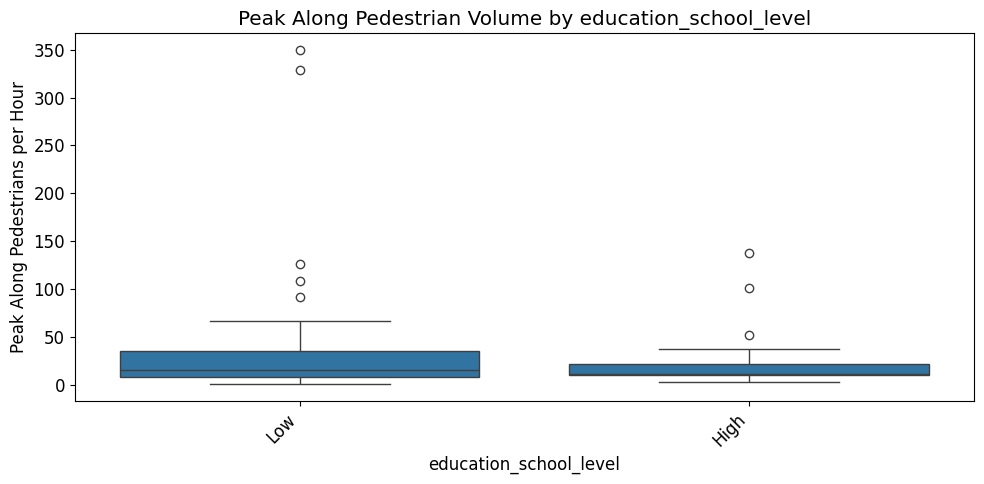

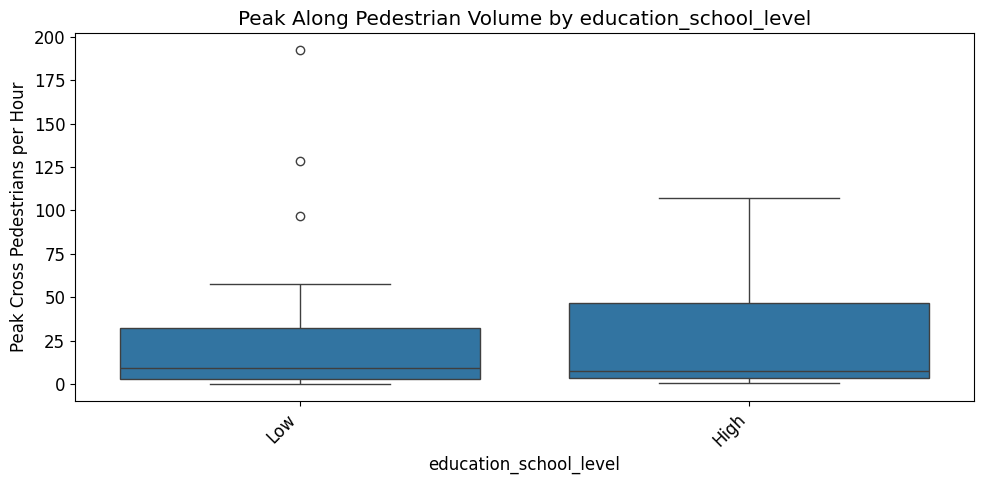

In [88]:
plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df_copy,
        x='education_school_level',
        y='obs_peak_along_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_school_level')
plt.xlabel('education_school_level')
plt.ylabel('Peak Along Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(
        data=df_copy,
        x='education_school_level',
        y='obs_peak_cross_ped_per_h'
    )

plt.title(f'Peak Along Pedestrian Volume by education_school_level')
plt.xlabel('education_school_level')
plt.ylabel('Peak Cross Pedestrians per Hour')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Based on these findings, the top five features—commercial buildings, food and drink outlets, parking areas, grocery and convenience stores, and other shopping amenities—were selected for modelling. This approach ensures the model remains parsimonious while retaining the variables most strongly linked to pedestrian activity.

In [89]:
# Add the two target variables
num_corr = num.copy()
num_corr['y_cross'] = y_cross
num_corr['y_along'] = y_along

# Correlation of numerical variables with the targets
target_corr = num_corr.corr()[['y_along', 'y_cross']]

target_corr.sort_values('y_along', ascending=False)

,y_along,y_cross
y_along,1.000000,0.840922
y_cross,0.840922,1.000000
commercial_buildings,0.770345,0.664348
overture_food_drink_count_500m,0.587476,0.573633
parking_areas,0.458351,0.423049
overture_grocery_convenience_pharmacy_count_500m,0.424042,0.386482
overture_other_shopping_count_500m,0.421943,0.291166
pedestrian_crossings,0.184487,0.230393
ms_building_coverage_ratio_500m,0.116288,0.100029
ms_building_footprint_area_m2_500m,0.116288,0.100029


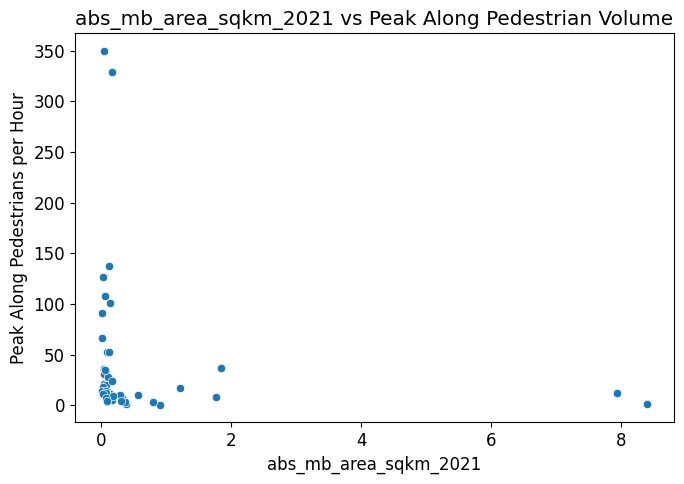

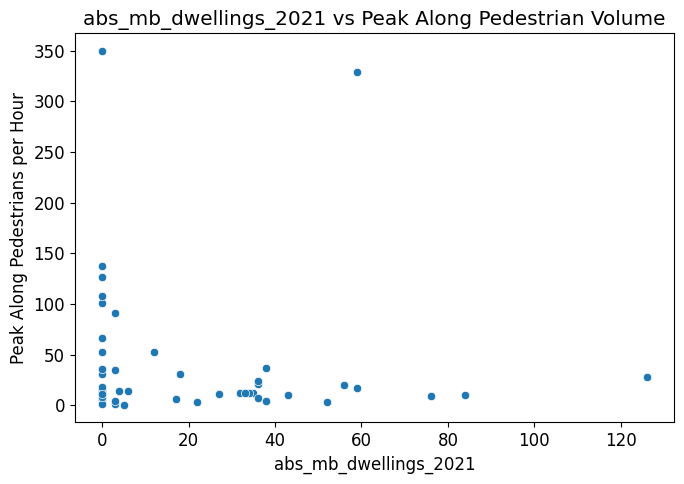

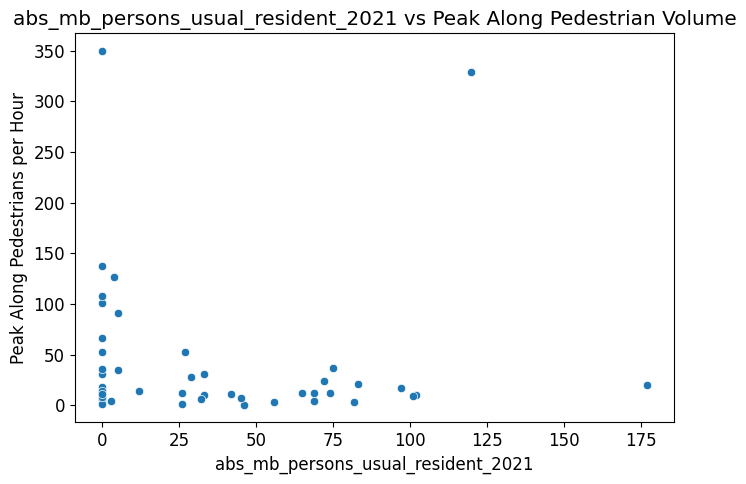

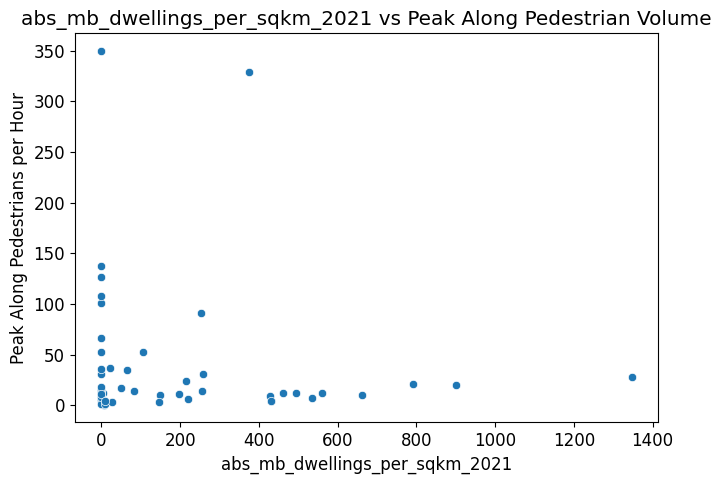

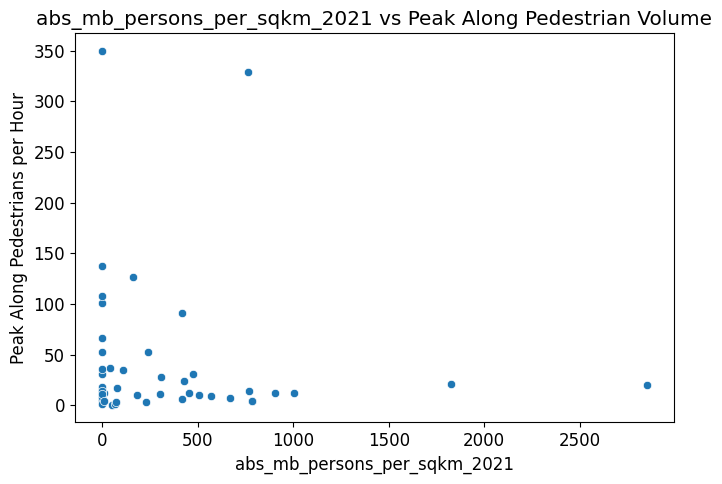

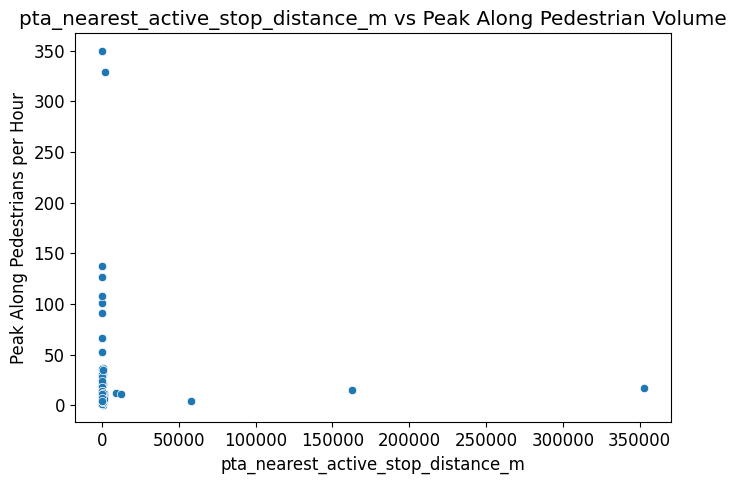

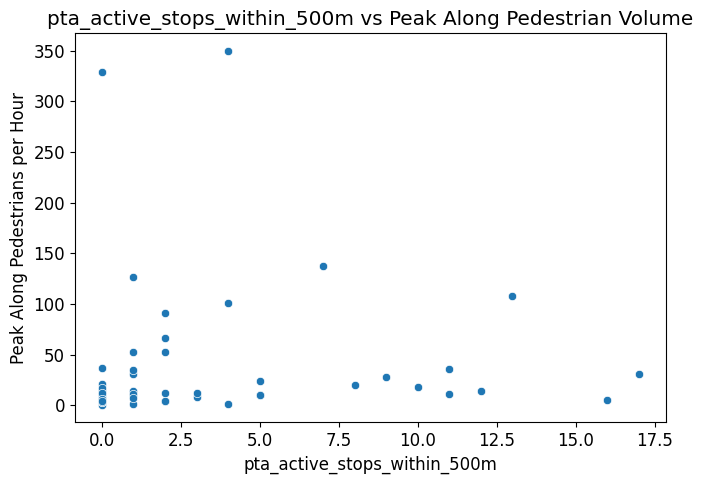

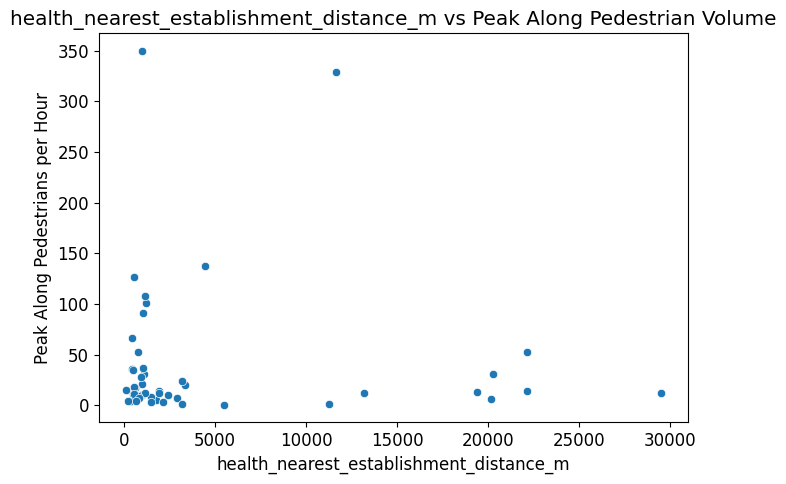

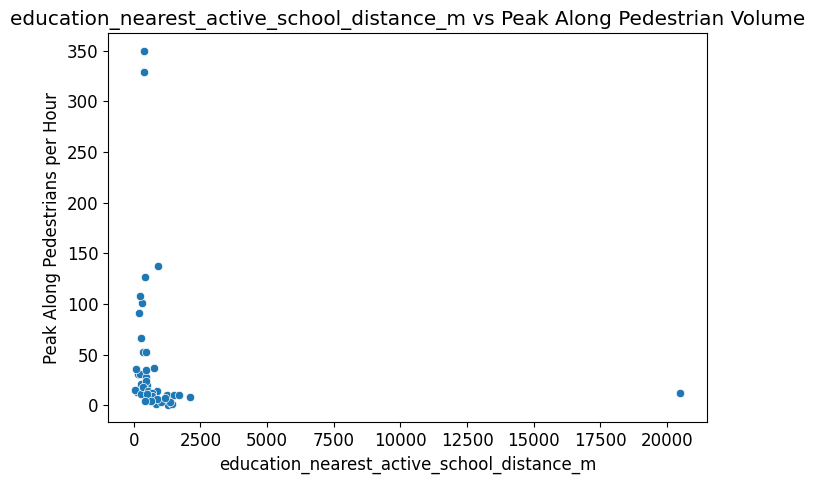

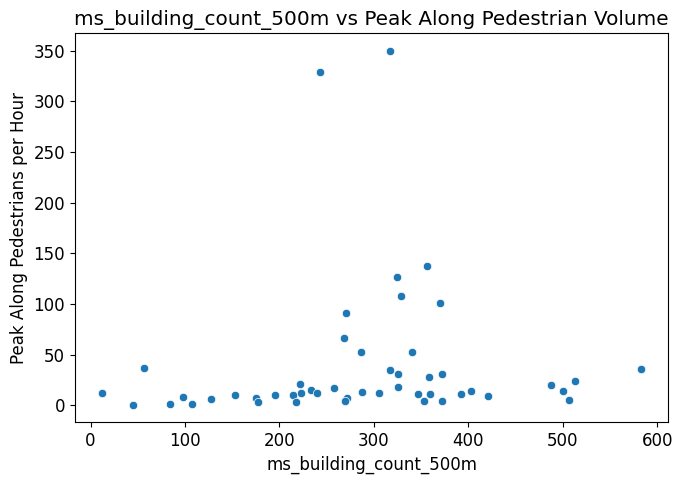

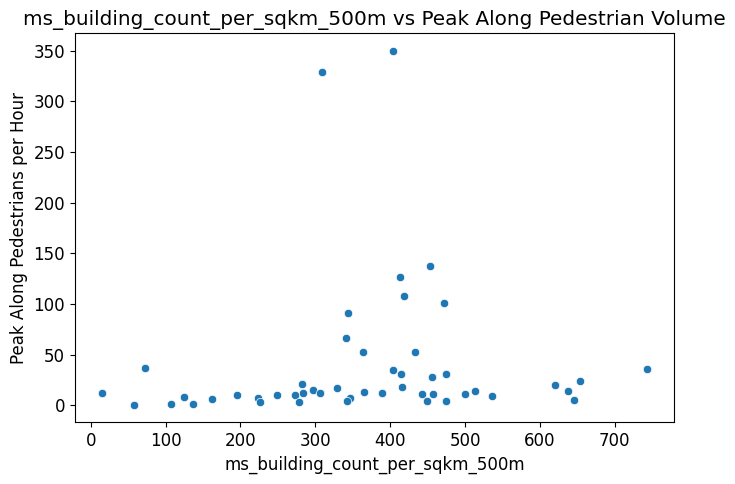

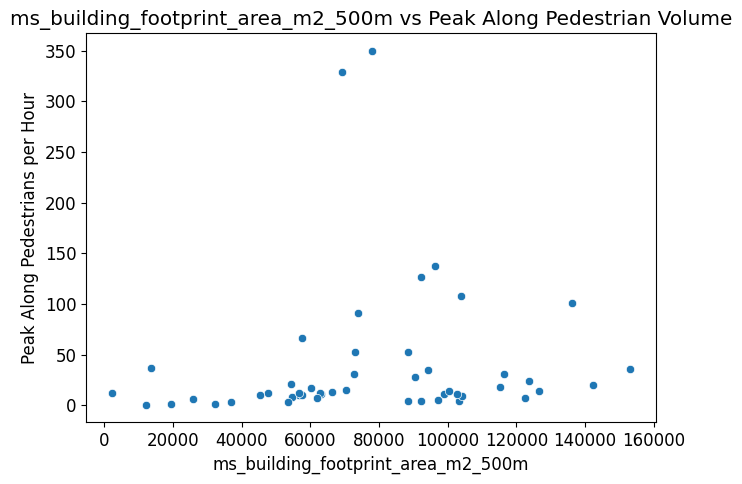

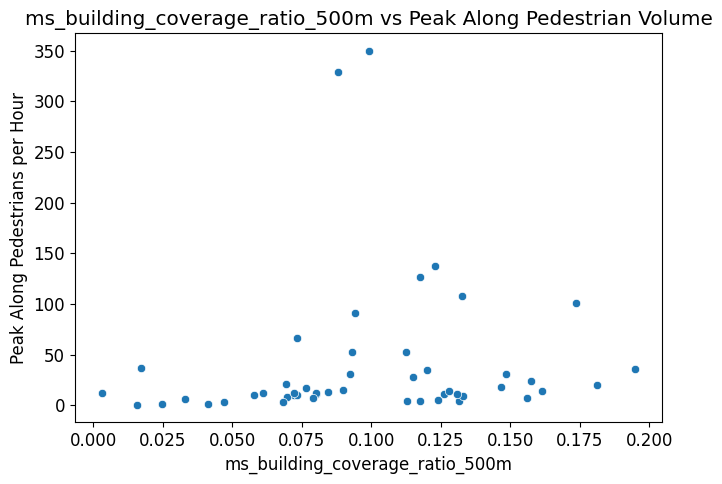

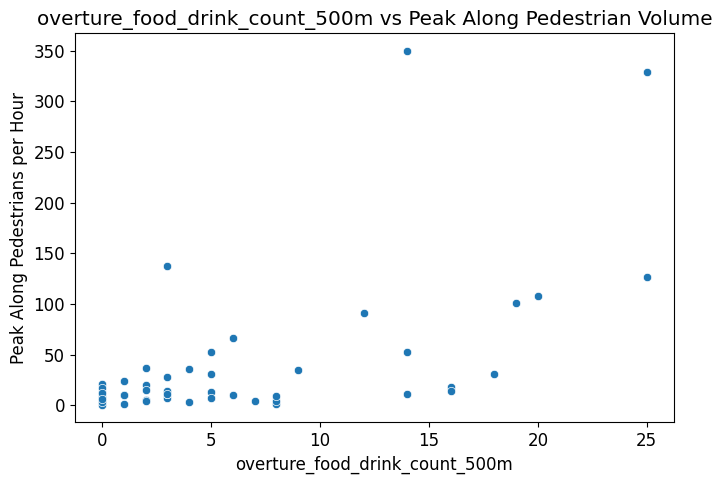

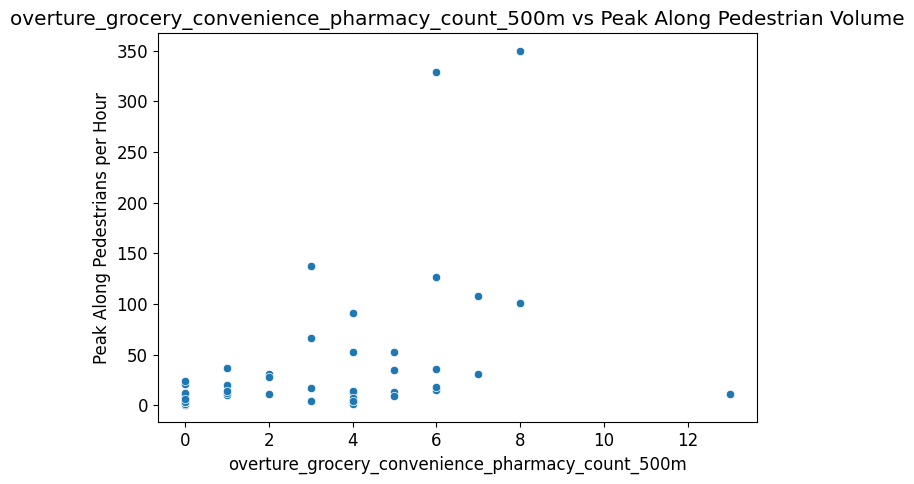

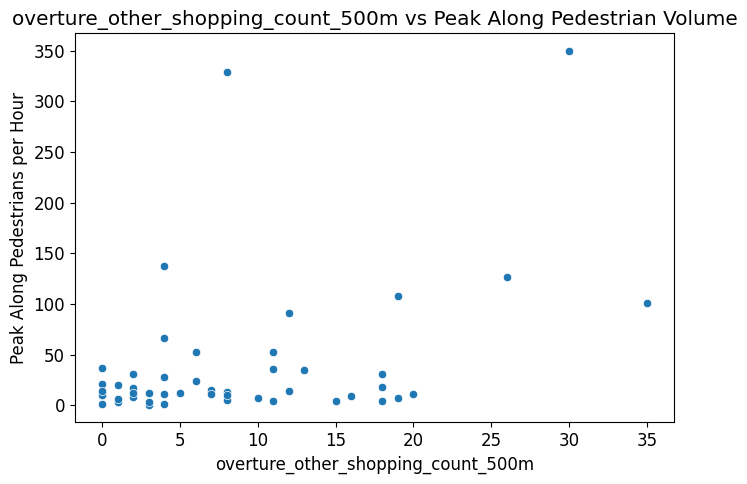

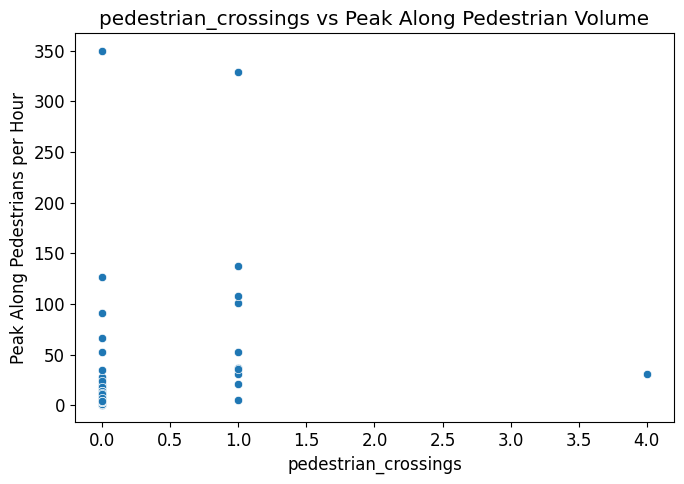

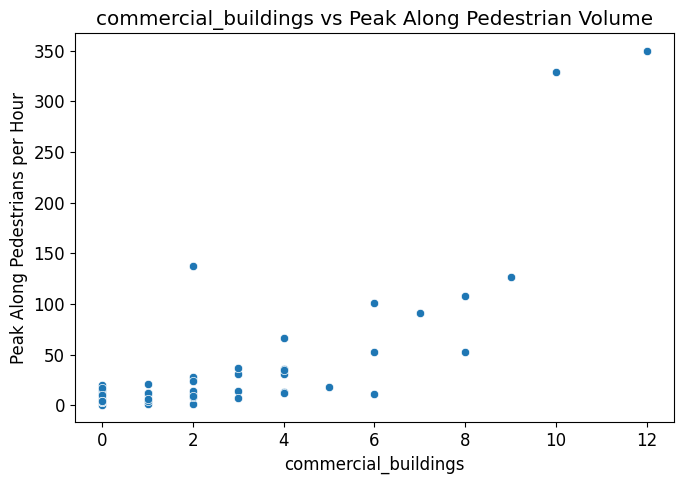

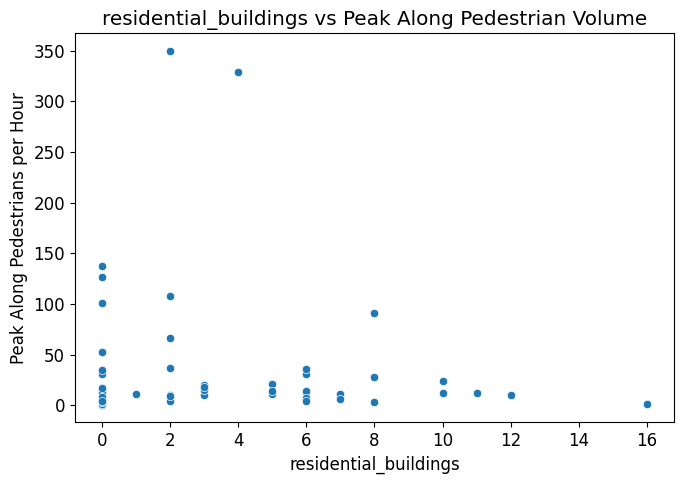

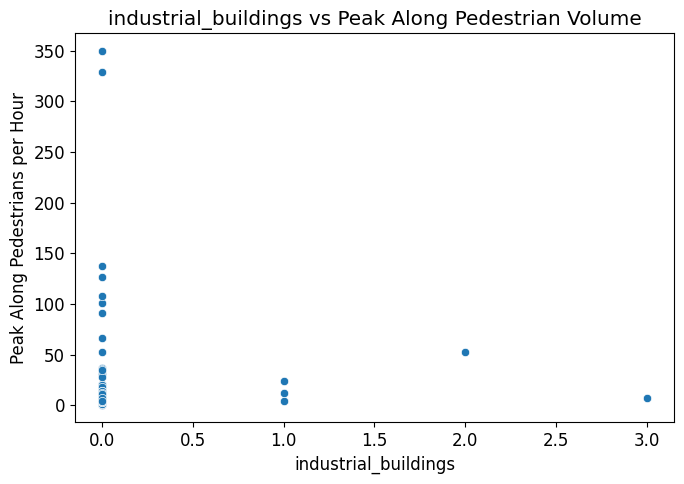

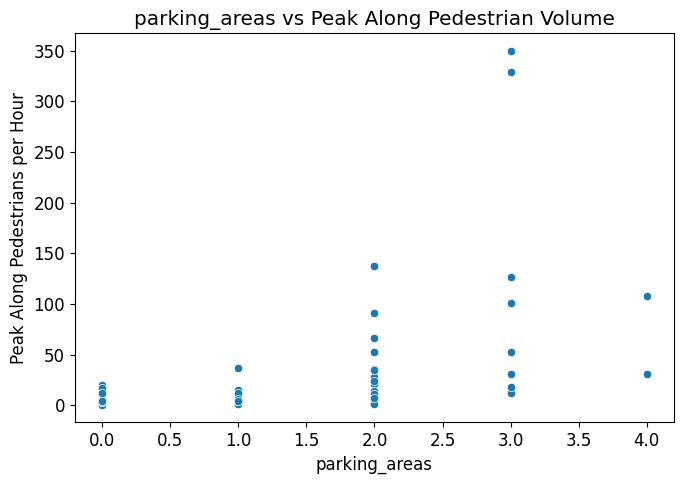

In [90]:
for col in num.columns:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=col,
        y=y_along
    )

    plt.title(f'{col} vs Peak Along Pedestrian Volume')
    plt.xlabel(col)
    plt.ylabel('Peak Along Pedestrians per Hour')
    plt.tight_layout()
    plt.show()

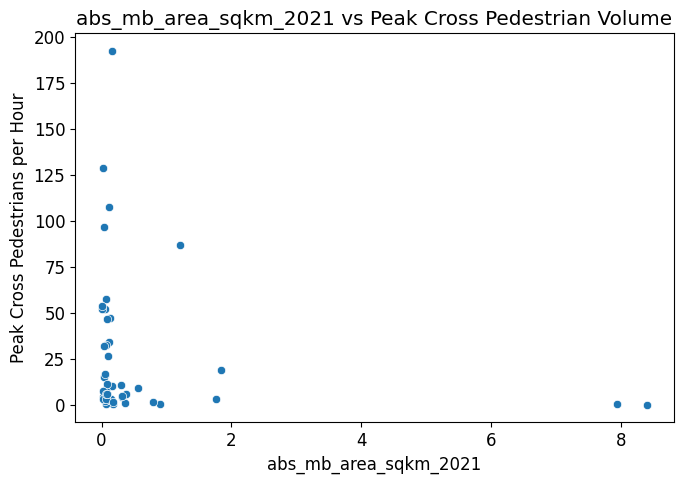

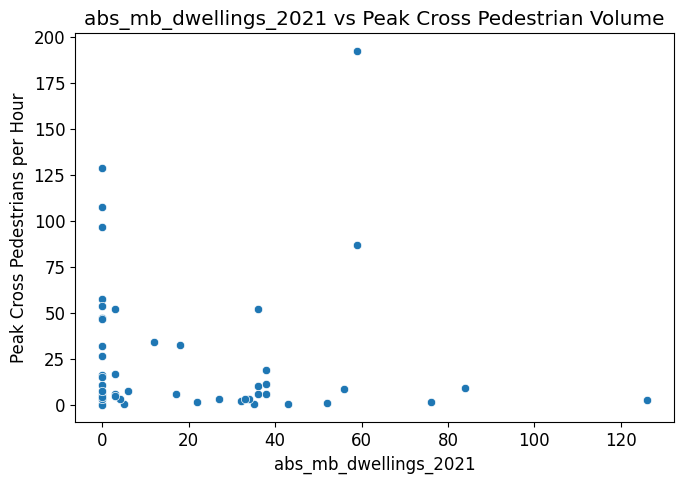

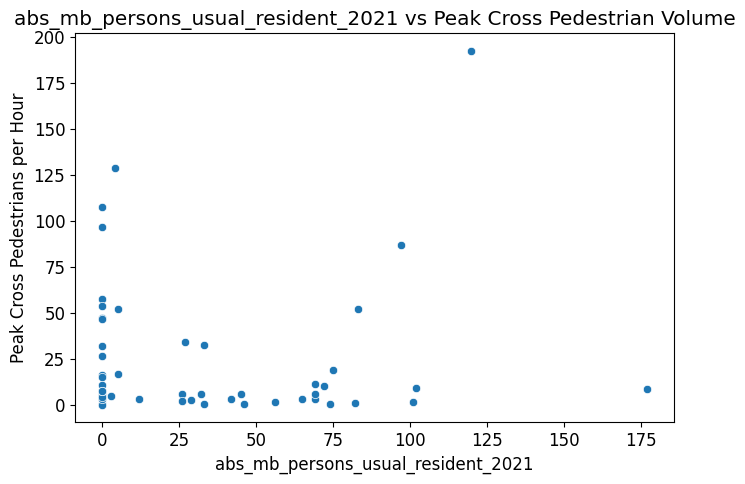

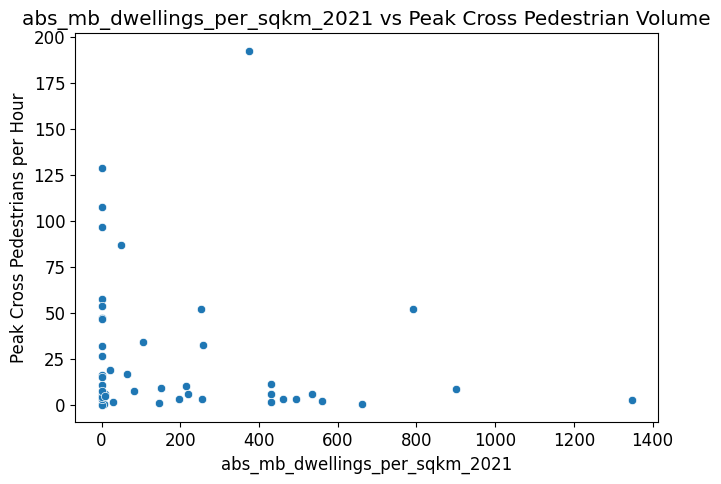

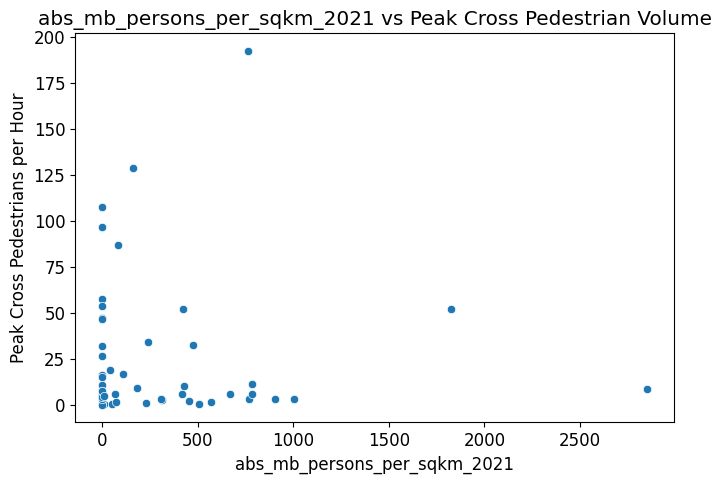

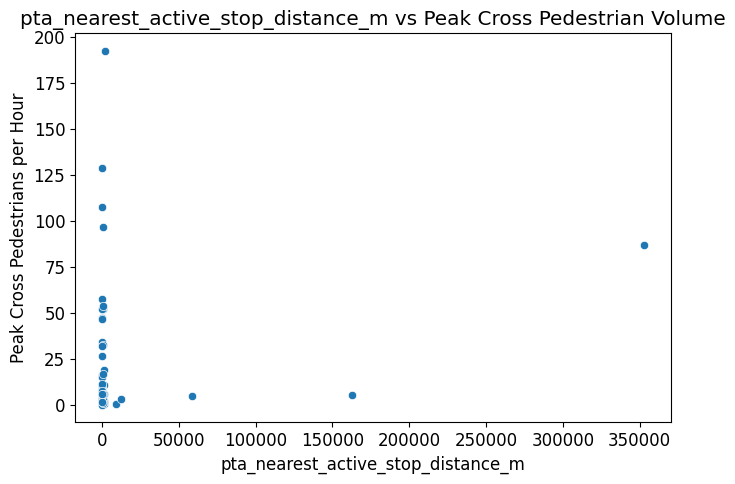

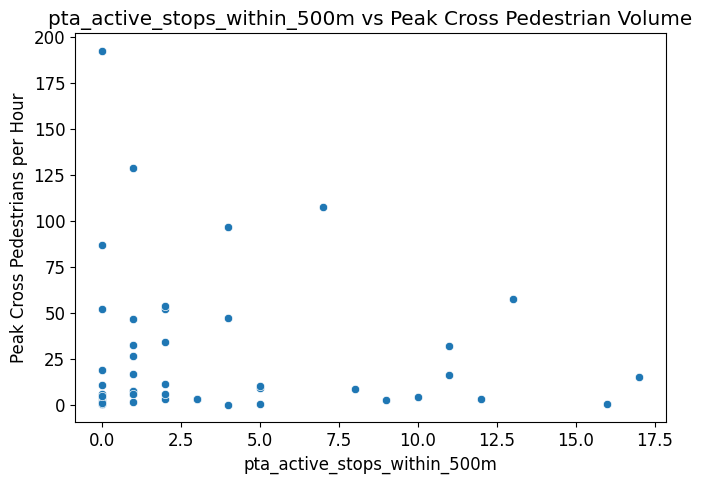

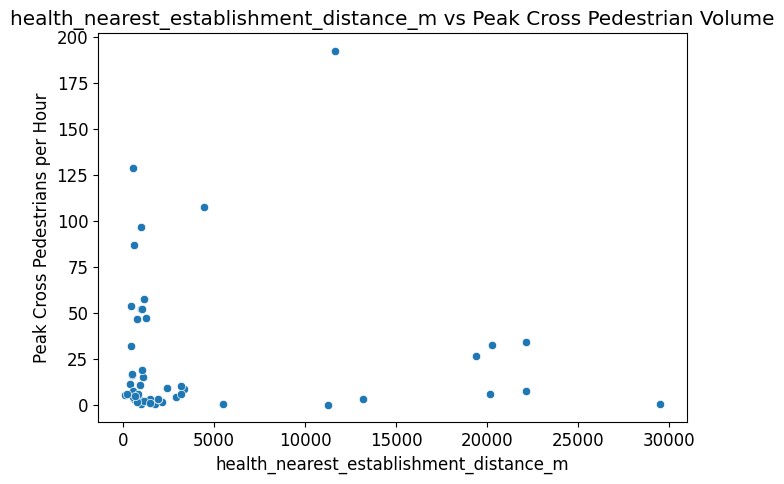

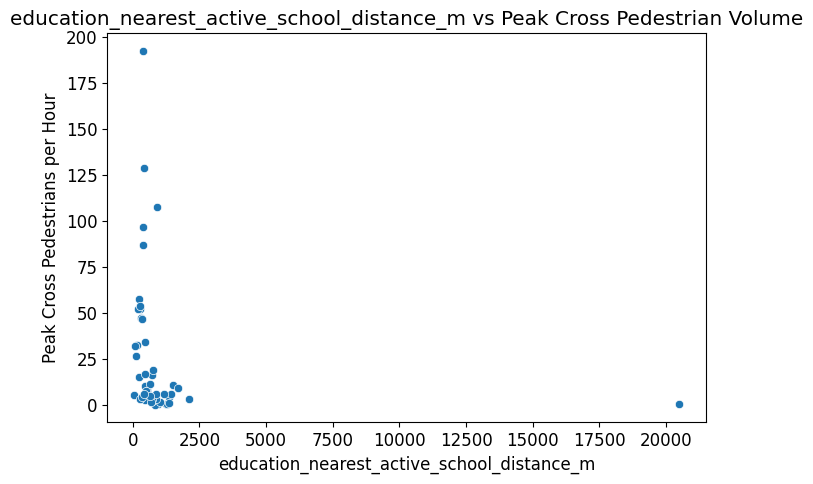

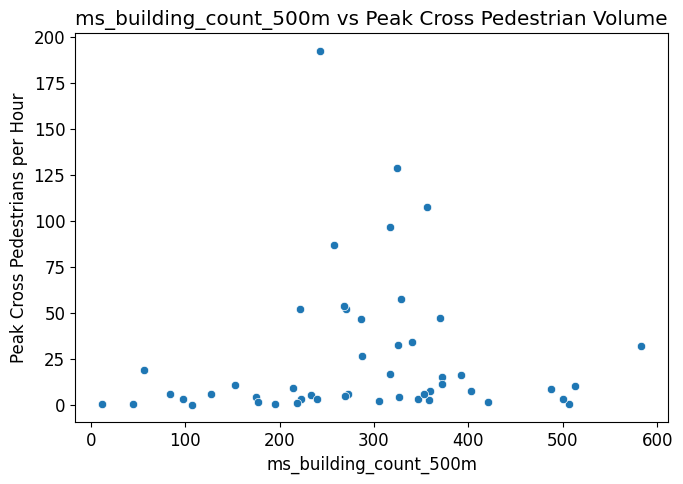

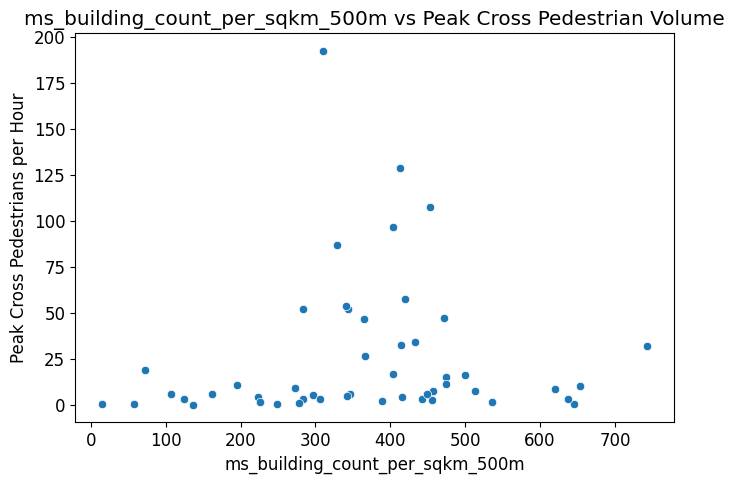

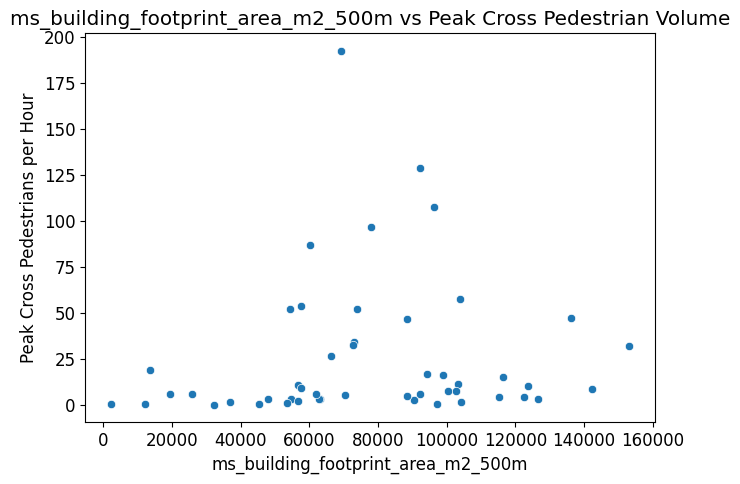

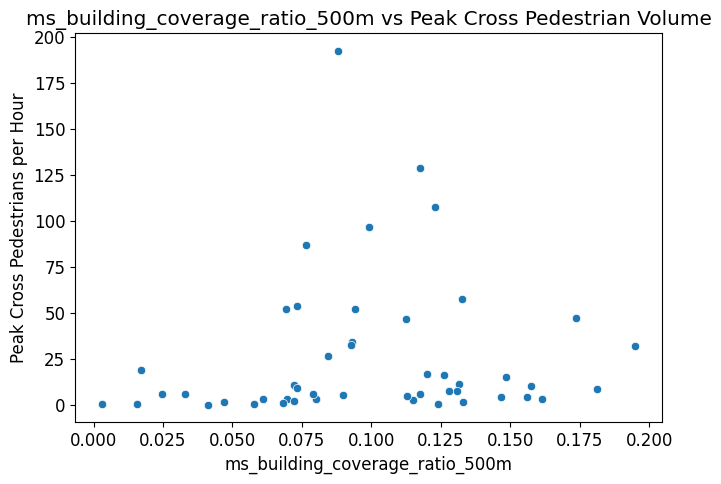

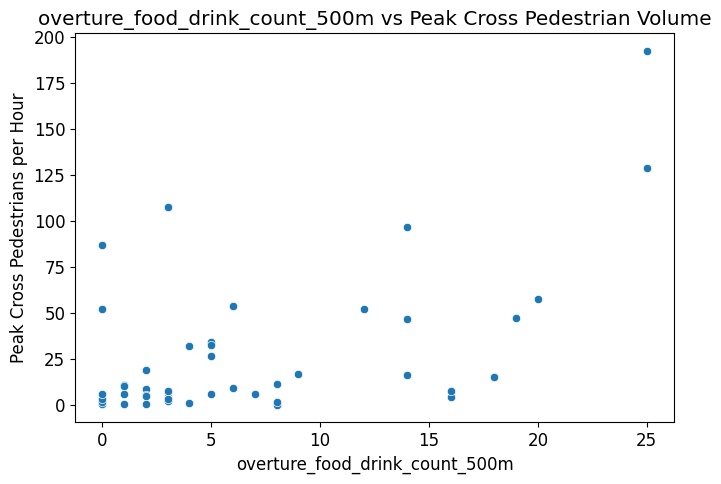

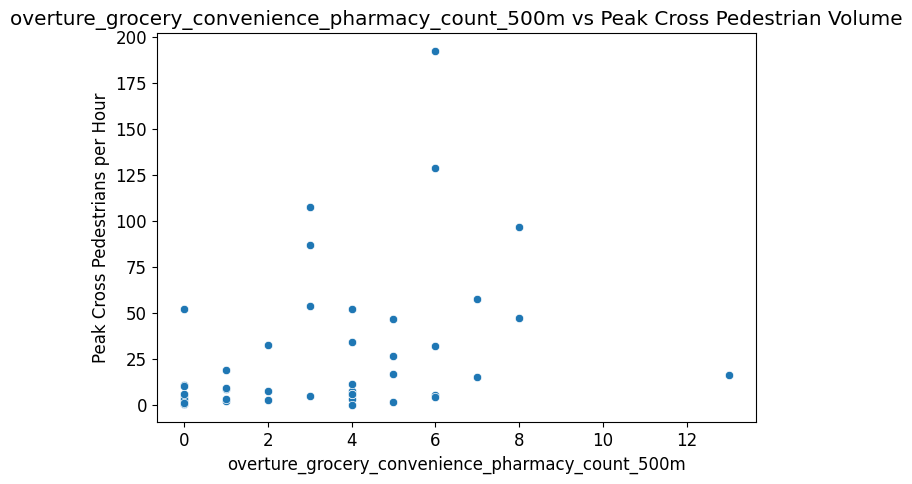

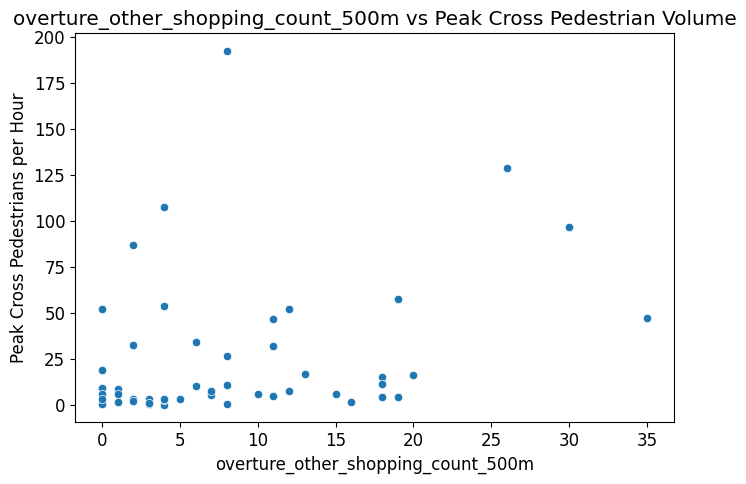

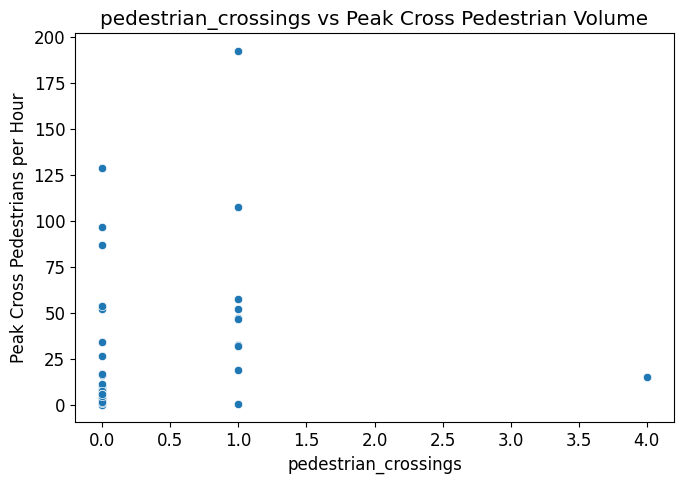

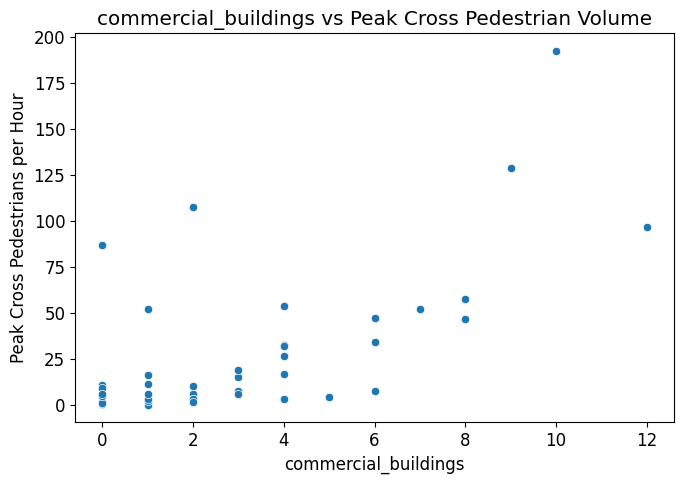

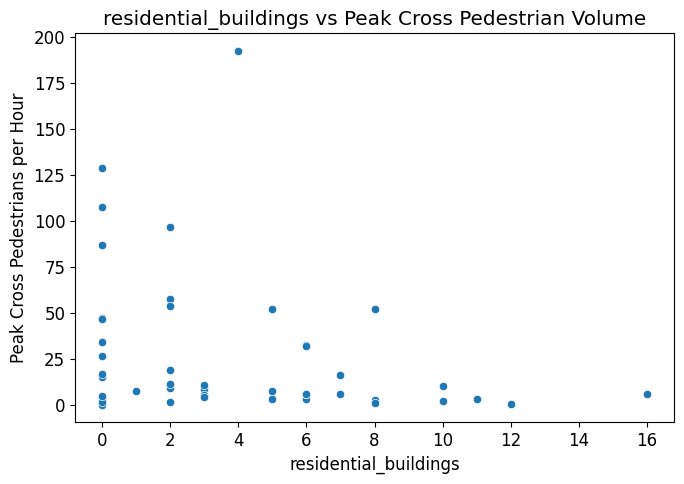

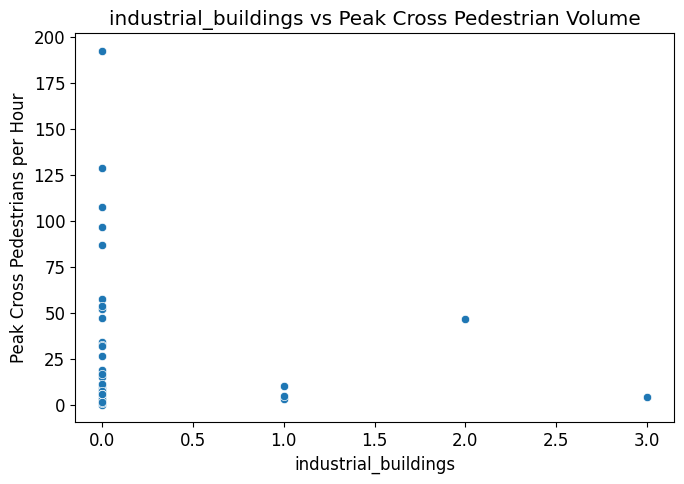

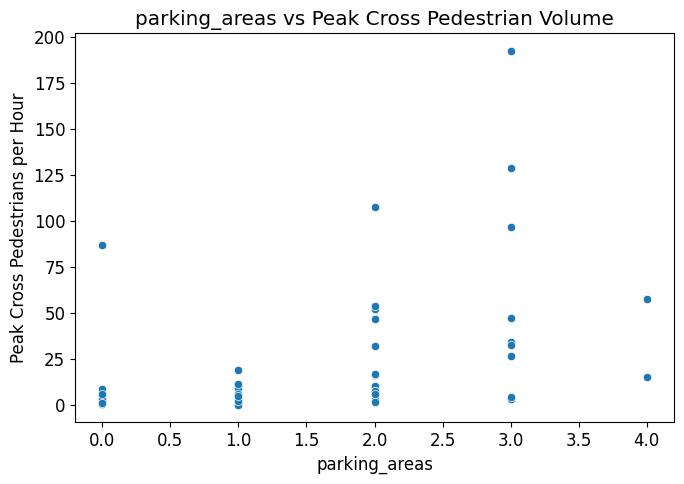

In [91]:
for col in num.columns:
    plt.figure(figsize=(7, 5))

    sns.scatterplot(
        data=df,
        x=col,
        y=y_cross
    )

    plt.title(f'{col} vs Peak Cross Pedestrian Volume')
    plt.xlabel(col)
    plt.ylabel('Peak Cross Pedestrians per Hour')
    plt.tight_layout()
    plt.show()

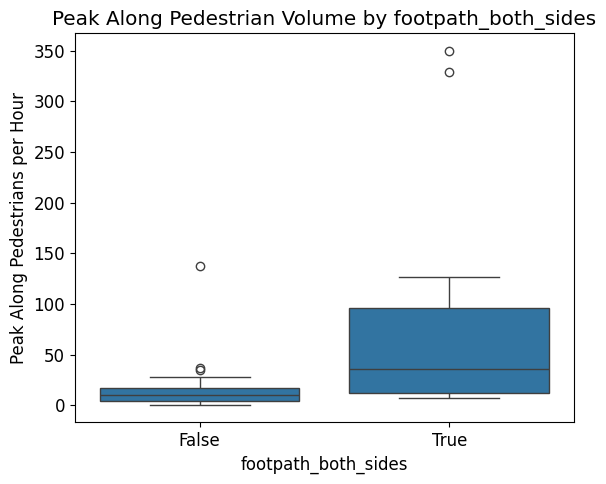

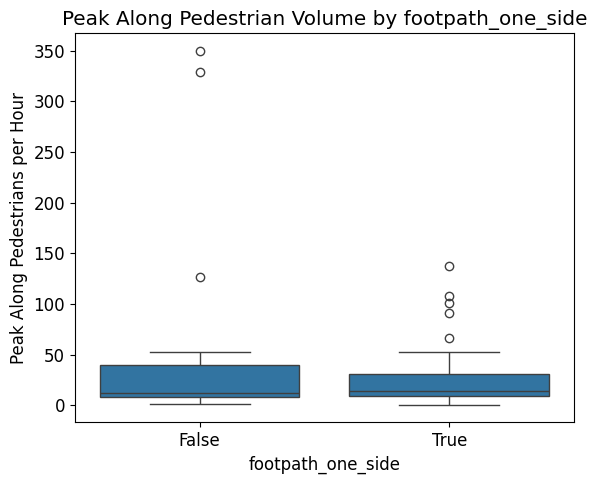

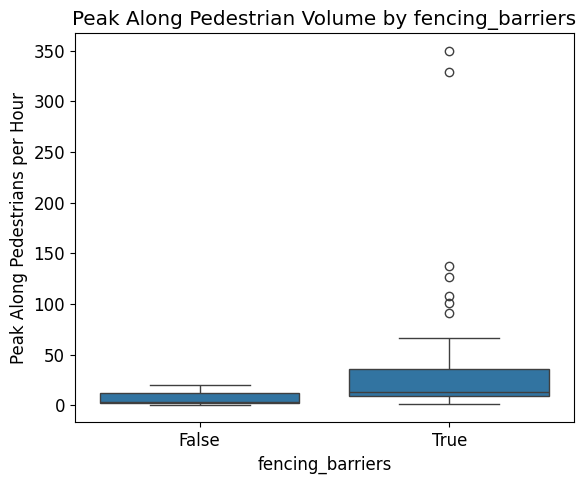

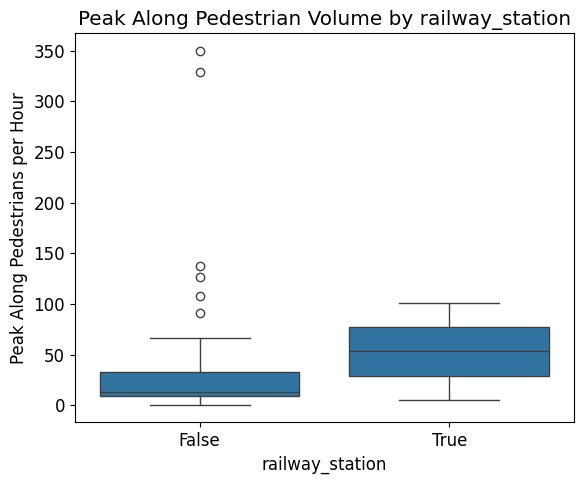

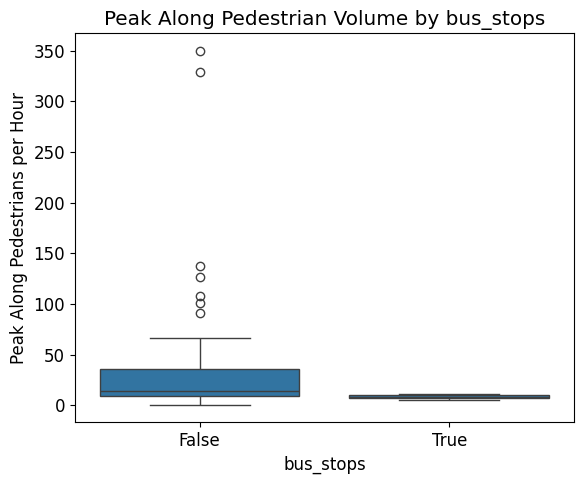

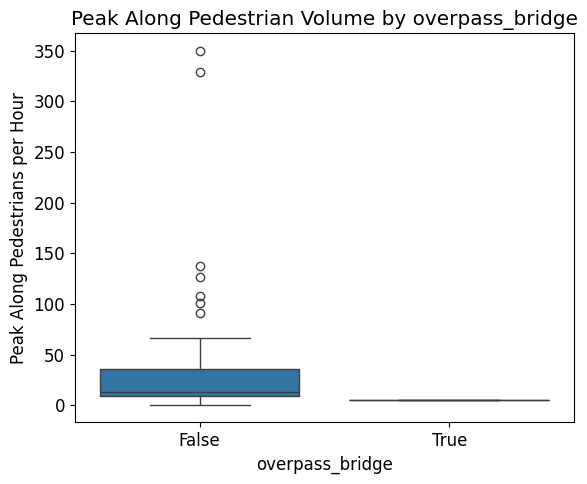

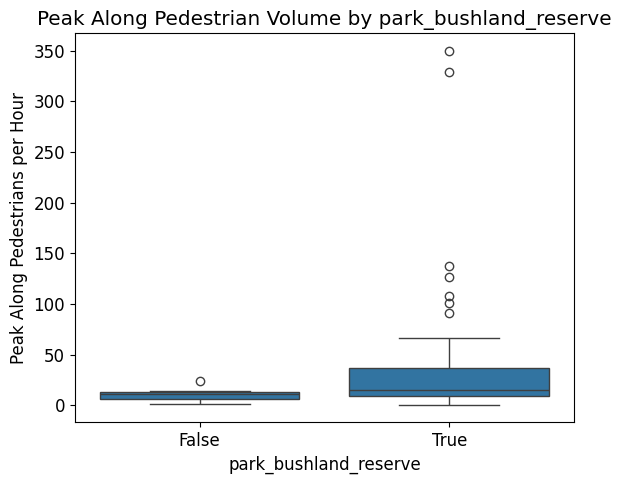

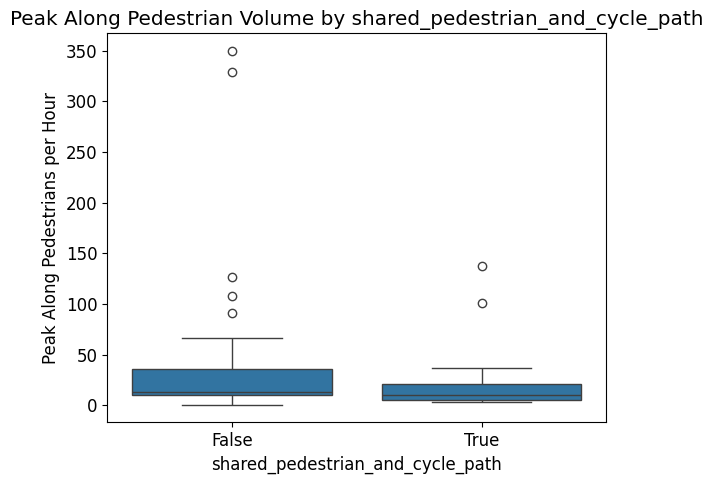

In [92]:
# Mean y_along for True and False
for col in bool_cols:
    plt.figure(figsize=(6, 5))

    sns.boxplot(
        data=df,
        x=col,
        y='obs_peak_along_ped_per_h'
    )

    plt.title(f'Peak Along Pedestrian Volume by {col}')
    plt.xlabel(col)
    plt.ylabel('Peak Along Pedestrians per Hour')
    plt.tight_layout()
    plt.show()

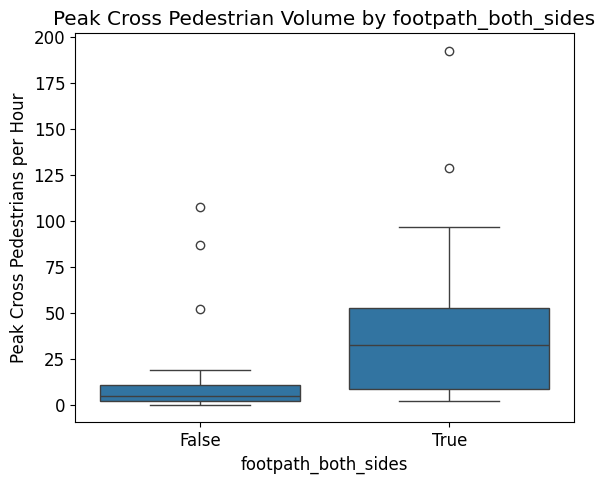

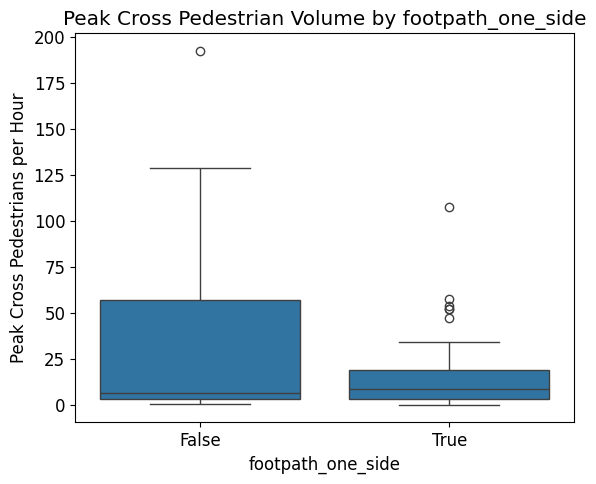

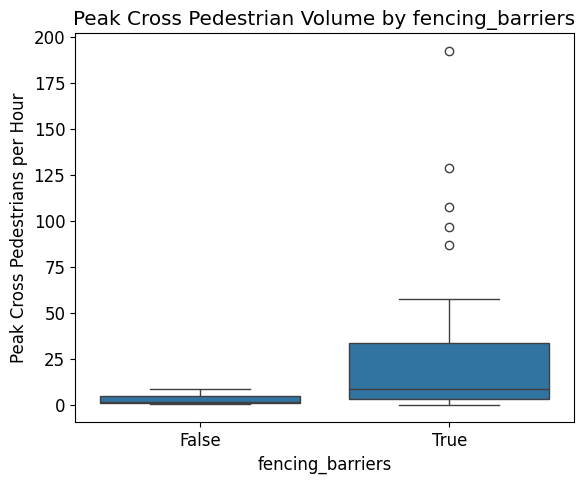

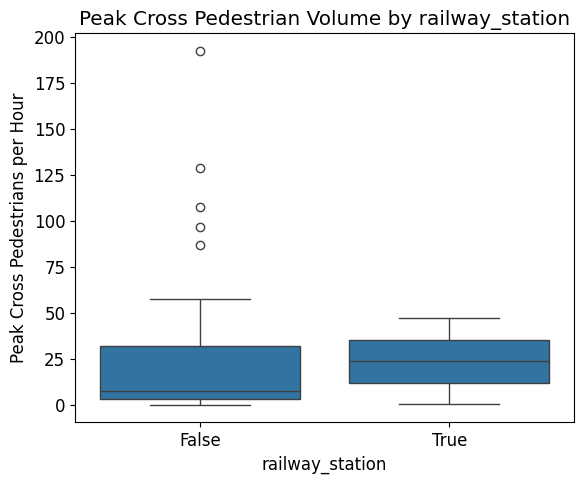

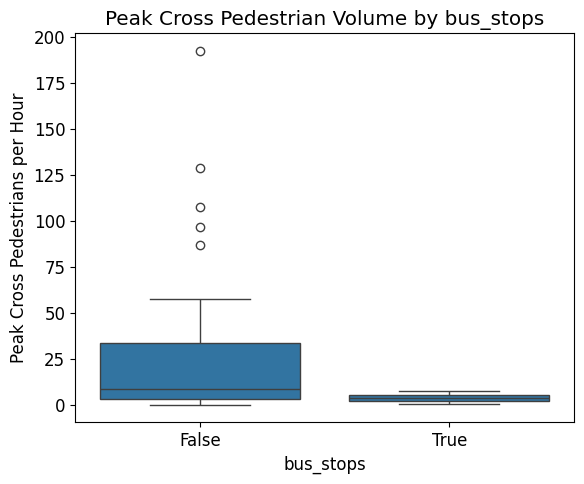

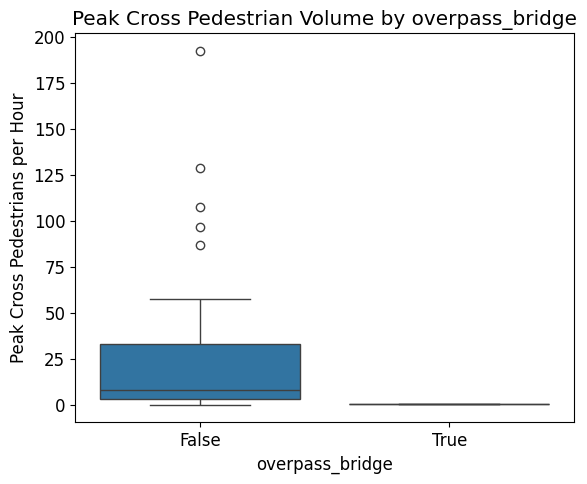

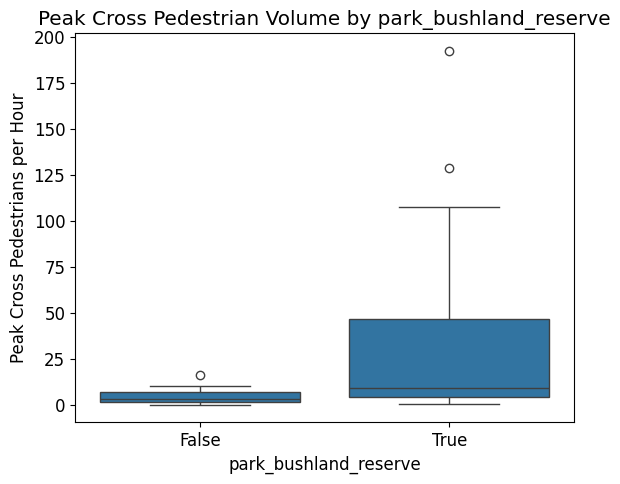

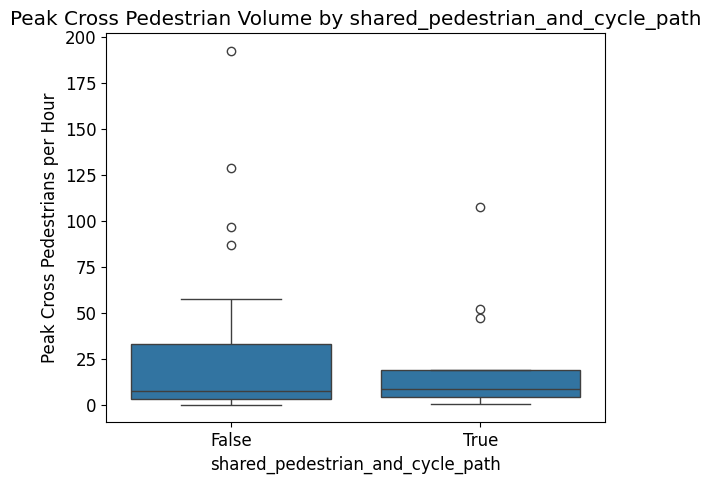

In [93]:
for col in bool_cols:
    plt.figure(figsize=(6, 5))

    sns.boxplot(
        data=df,
        x=col,
        y='obs_peak_cross_ped_per_h'
    )

    plt.title(f'Peak Cross Pedestrian Volume by {col}')
    plt.xlabel(col)
    plt.ylabel('Peak Cross Pedestrians per Hour')
    plt.tight_layout()
    plt.show()

footpath_both_sides — strong positive effect; pedestrian volumes are much higher when both sides have footpaths.

fencing_barriers — moderate positive effect; higher pedestrian counts likely due to controlled or channelled movement.

railway_station — clear positive association; transit hubs naturally attract pedestrian activity.

park_bushland_reserve — slight positive effect; recreational areas draw more foot traffic.

The others — footpath_one_side, bus_stops, overpass_bridge, and shared_pedestrian_and_cycle_path — show little or no difference, meaning they don’t meaningfully predict pedestrian volume.

In [94]:
cat_cols = [
    'abs_mb_category_2021',
    'health_nearest_establishment_category'
]

num_cols = [
    'overture_food_drink_count_500m',
    'overture_grocery_convenience_pharmacy_count_500m',
    'overture_other_shopping_count_500m',
    'commercial_buildings',
    'parking_areas'

]

bool_cols = [
    'footpath_both_sides',
    'fencing_barriers',
    'railway_station',
    'park_bushland_reserve'

]

cat = df_copy[cat_cols]
num = df_copy[num_cols]
bool_var = df_copy[bool_cols]
y_cross = df_copy['obs_peak_cross_ped_per_h']
y_along = df_copy['obs_peak_along_ped_per_h']

In [95]:
data = pd.concat([cat, num, bool_var], axis=1)
data.head(5)

,abs_mb_category_2021,health_nearest_establishment_category,overture_food_drink_count_500m,overture_grocery_convenience_pharmacy_count_500m,overture_other_shopping_count_500m,commercial_buildings,parking_areas,footpath_both_sides,fencing_barriers,railway_station,park_bushland_reserve
0,Residential,Acute Hospital,0,0,0,0,0,False,True,False,True
1,Industrial,Acute Hospital,3,0,19,0,1,True,True,False,True
2,Transport,Acute Hospital,19,8,35,6,3,True,True,True,True
3,Commercial,Acute Hospital,14,13,20,1,2,False,True,False,False
4,Commercial,Acute Hospital,20,7,19,8,4,True,True,False,True


I selected these features based on clear patterns observed during exploratory data analysis. The numerical variables showed the strongest positive correlations with pedestrian volumes, indicating they are the most influential predictors. The boolean infrastructure features demonstrated visibly higher pedestrian counts in the box plots, confirming their relevance for modelling. The categorical variables were retained to capture essential contextual land‑use differences that shape pedestrian behaviour. Together, these choices create a parsimonious feature set that is both data‑driven and behaviourally meaningful for predicting pedestrian activity.